# Elección de la ubicación de los polos a lazo cerrado

## Sistema de segundo orden dominante

Una forma de seleccionar la ubicación de los polos es hacer lo mismo que se hacía en control clásico, es decir buscar que el sistema sea parecido a un segundo orden dominante.

Esto es perfectamente factible en control moderno. Sin embargo, tiene la desventaja de que no sabemos qué sucederá con el esfuerzo de control $u$. Ubicando los polos de esta manera podemos obtener esfuerzos de control imposibles de realizar por nuestros actuadores, o que lleven a consumos de energías demasiado altos para nuestro sistema.

Por esto, lo más recomendable es usar técnicas de control óptimo para seleccionar los polos del sistema a lazo cerrado.

## Lugar simétrico de las raíces

Una técnica de control óptimo ampliamente usada es el regulador cuadrático lineal (LQR, por sus siglas en inglés). En este curso veremos una versión simplificada que se conoce como __Lugar de las Raíces Simétrico__. Esta versión simplificada consiste en resolver el problema de minimización del siguiente índice de costo:

$$\mathcal J = \int_0^{\infty}\left[\rho z^2(t)+u^2(t)\right]dt$$

donde:

$$
\mathbf{\dot x} = \mathbf{Ax}+\mathbf B u\\
z =  \mathbf{C_1x}\\
$$

mediante la ley de control:

$$ u =-\mathbf{Kx}$$

Se puede demostrar que los polos a lazo cerrado que minimizan el funcional de costo anterior son los polos estables del lugar simétrico de las raíces dado por la ecuación:

$$1+\rho G_0(-s)G_0(s)=0$$

donde $G_0(s)$ es:

$$G_0(s) = \frac{Z(s)}{U(s)}=\mathbf{C_1}(s\mathbf I -\mathbf A)^{-1}\mathbf B$$

Por lo tanto el problema lo podemos resolver para todo $\rho$ haciendo un lugar de las raíces de $G_0(-s)G_0(s)$. El lugar será simétrico respecto del eje $j\omega$, ya que los polos y ceros de $G_0(-s)G_0(s)$ también están ubicados de forma simétrica.

## Ejemplo: elección de los polos de la ley de control

Dado el sistema con las siguientes ecuaciones de estado:

$$\dot{\mathbf{x}}(t) = \begin{bmatrix} -3 & 2 \\ -1 & 0 \end{bmatrix} \mathbf{x}(t) + \begin{bmatrix} 1 \\ 0 \end{bmatrix} u(t) $$

$$ y(t) = \begin{bmatrix} 1& -3 \end{bmatrix} \mathbf{x}(t) $$

Obtener leyes de control (una por cada ítem) que cumplan con las siguientes especificaciones:
- que el tiempo de establecimiento sea menor a 0.8 segundos y que el sobrevalor sea menor a 10%,
- igual que el anterior, pero diseñando con el lugar simétrico de las raíces,
- también con el lugar simétrico de las raíces, pero con un $\rho$ 10 veces más grande que el anterior.

In [1]:
import control as ctrl
import numpy as np
import matplotlib.pyplot as plt

Definimos primero las matrices del sistema:

In [2]:
A=[[-3, 2],[-1,0]]
B=[[1],[0]]
C=[[1,-3]]
D=0

y ahora definimos el sistema con el módulo de `control`.

In [3]:
sys = ctrl.ss(A,B,C,D)
ctrl.tf(sys)

TransferFunction(
array([1., 3.]),
array([1., 3., 2.]),
outputs=1, inputs=1)

### Ubicando los polos con el criterio de 2do orden dominante

Usando el criterio de hacer el sistema de segundo orden dominante, pondremos los polos en la posición que correspondería a ese segundo orden. Para eso buscamos la zona del plano $s$ que cumple con el tiempo de establecimiento solicitado (se asume al 2%):

In [4]:
ts = 0.8
sigma=4/ts # al 2%
sigma

5.0

Ahora se busca la zona que cumple con el sobrevalor:

In [5]:
# SV menor al 10%
zeta=0.6
np.exp(-np.pi*zeta/(np.sqrt(1-zeta**2)))

np.float64(0.09478022484215486)

Obtenemos los polos objetivos:

In [6]:
wn=sigma/zeta
wd=wn*np.sqrt(1-zeta**2)
pobj=-sigma+1j*wd
pobj

(-5+6.666666666666668j)

In [7]:
K1=np.atleast_2d(ctrl.acker(sys.A, sys.B, [pobj, pobj.conjugate()]))
K1

array([[  7.        , -67.44444444]])

In [8]:
sys_ley_control1 = ctrl.ss(sys.A-sys.B@K1, [[0],[0]], sys.C, 0)
sys_ley_control1.poles()

array([-5.+6.66666667j, -5.-6.66666667j])

o también lo podemos verificar como:

In [9]:
np.linalg.eigvals(sys_ley_control1.A)

array([-5.+6.66666667j, -5.-6.66666667j])

### Utilizando el criterio del lugar simétrico de las raíces

Como en el enunciado no se nos da ningún indicio de cómo tomar $z(t)$ para utilizar en el criterio, utilizaremos $z(t)=y(t)$, por lo que $\mathbf{C}_1=\mathbf{C}$, y por ende $G_0(s) = G(s)$. Entonces obtenemos $G(s)$:

In [10]:
G=ctrl.tf(sys)
G

TransferFunction(
array([1., 3.]),
array([1., 3., 2.]),
outputs=1, inputs=1)

Por inspección podemos obtener el $G(-s)$:

In [11]:
Gm = ctrl.tf([-1,3],[1,-3,2])
Gm

TransferFunction(
array([-1,  3]),
array([ 1, -3,  2]),
outputs=1, inputs=1)

A continuación se presenta una función que obtiene $G(-s)$ de un sistema SISO del módulo de `control` de Python. Reemplazar $s$ por $-s$ equivale a cambiar el signo de los coeficientes de las potencias impares de $s$.

In [12]:
def conjugate_tf(G):
    num = ctrl.tf(G).num[0][0]
    den = ctrl.tf(G).den[0][0]
    # el coeficiente i multiplica a s^(n-1-i)
    nume = [c*(-1)**(len(num)-1-i) for i, c in enumerate(num)]
    dene = [c*(-1)**(len(den)-1-i) for i, c in enumerate(den)]
    return ctrl.tf(nume, dene)

Probamos esa función:

In [13]:
Gm=conjugate_tf(G)
Gm

TransferFunction(
array([-1.,  3.]),
array([ 1., -3.,  2.]),
outputs=1, inputs=1)

Ahora podemos trazar el lugar simétrico de las raíces (LSR).

In [14]:
%matplotlib inline

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


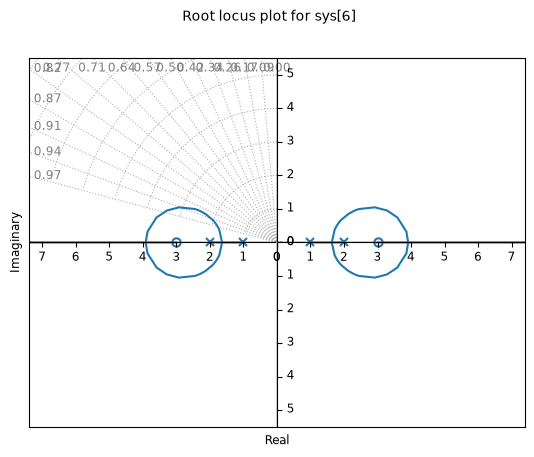

In [15]:
ctrl.rlocus(G*Gm);

Podemos ver en la figura que los objetivos se logran usando polos reales: uno lo podemos ubicar cerca de $-5$ y el otro queda cerca del cero del sistema en $-3$, por lo que es esperable que no afecte demasiado el comportamiento.

Para obtener los polos del lugar para un valor dado de $\rho$ usamos `root_locus_map`:

In [16]:
r = ctrl.root_locus_map(G*Gm, gains=[32]).loci[0]
pobj= r[np.real(r)<0]
pobj

array([-5.05852977, -3.3780581 ])

In [17]:
K2 = ctrl.place(sys.A, sys.B, pobj)
K2

array([[  5.43658788, -15.08800749]])

Finalmente cerramos el lazo con esta ley de control

In [18]:
sys_ley_control2 = ctrl.ss(sys.A-sys.B@K2, [[0],[0]], sys.C, 0)
sys_ley_control2.poles()

array([-5.05852977+0.j, -3.3780581 +0.j])

Podemos ver que esta ley de control tiene ganancias mucho menores que la obtenida anteriormente.

### Ley de control usando un $\rho$ 10 veces más grande.

Al hacer más grande a $\rho$ se está pesando más las desviaciones del sistema medidas en $z(t)$ que el esfuerzo de control $u(t)$, por lo que es de esperar que este sistema sea bastante más rápido que el obtenido anteriormente. También es de esperar que los movimientos en $u(t)$ sean mayores.

De lo dicho en la teoría, aumentar 10 veces $\rho$ es aumentar 10 veces la ganancia $k$ para la cual se obtienen los polos del lugar simétrico de las raíces.

El $\rho$ obtenido en el punto anterior fue de 32. Entonces ahora usaremos un $\rho$ de 320.

In [19]:
r = ctrl.root_locus_map(G*Gm, gains=[320]).loci[0]
pobj= r[np.real(r)<0]
pobj

array([-17.77272212,  -3.02164665])

In [20]:
K3 = ctrl.place(sys.A, sys.B, pobj)
K3

array([[ 17.79436877, -51.70288633]])

Y definimos el sistema controlado:

In [21]:
sys_ley_control3 = ctrl.ss(sys.A-sys.B@K3, [[0],[0]], sys.C, 0)
sys_ley_control3.poles()

array([-17.77272212+0.j,  -3.02164665+0.j])

### Comparación de los 3 sistemas controlados

Vamos a redefinir los 3 sistemas controlados para tener a la salida también la variable $u(t)$. Sabemos que $u(t) = -\mathbf{Kx}(t)$. Para verla en la salida, redefinimos la matriz $\mathbf{C}$ de forma que tenga una fila más igual a $-\mathbf{K}$:

In [22]:
C1 = np.vstack((sys_ley_control1.C,-K1))
sysf1=ctrl.ss(sys_ley_control1.A,
                sys_ley_control1.B,
                C1, [[0],[0]])

C2 = np.vstack((sys_ley_control2.C,-K2))
sysf2=ctrl.ss(sys_ley_control2.A,
                sys_ley_control2.B,
                C2, [[0],[0]])

C3 = np.vstack((sys_ley_control3.C,-K3))
sysf3=ctrl.ss(sys_ley_control3.A,
                sys_ley_control3.B,
                C3, [[0],[0]])

Ahora podemos simular la respuesta a condiciones iniciales no nulas:

In [23]:
t=np.linspace(0,2,501)
x0=[1,1]
t1,y1 = ctrl.initial_response(sysf1, T=t, X0=[1,1])
t2,y2 = ctrl.initial_response(sysf2, T=t, X0=[1,1])
t3,y3 = ctrl.initial_response(sysf3, T=t, X0=[1,1])

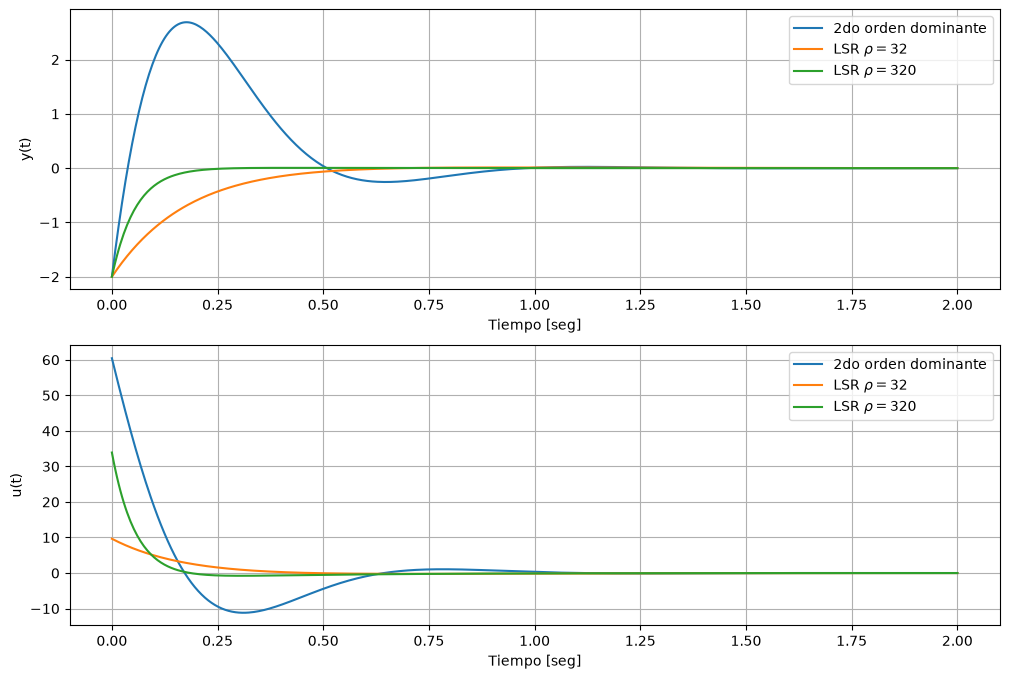

In [24]:
fig, ax = plt.subplots(2,1, figsize=(12,8))
ax[0].plot(t1, y1[0,:], label="2do orden dominante")
ax[0].plot(t2, y2[0,:], label=r"LSR $\rho=32$")
ax[0].plot(t3, y3[0,:], label=r"LSR $\rho=320$")
ax[0].grid()
ax[0].legend()
ax[0].set_xlabel('Tiempo [seg]')
ax[0].set_ylabel('y(t)')
ax[1].plot(t1, y1[1,:], label="2do orden dominante")
ax[1].plot(t2, y2[1,:], label=r"LSR $\rho=32$")
ax[1].plot(t3, y3[1,:], label=r"LSR $\rho=320$")
ax[1].grid()
ax[1].legend()
ax[1].set_xlabel('Tiempo [seg]')
ax[1].set_ylabel('u(t)');

Podemos ver que el cero del sistema arruina lo que esperábamos del criterio de segundo orden dominante.

Por otro lado, el sistema obtenido con el primer criterio de LSR no tiene sobrevalor, cumple (o está muy cerca de cumplir) con todas las especificaciones y usa una $u(t)$ significativamente menor que los otros dos casos.

Para el segundo caso del criterio LSR vemos que el sistema converge mucho más rápido que los casos anteriores. Aun así tiene menores movimientos de $u(t)$ que el caso 1. Esto es porque la posición de los polos objetivo fue elegida siguiendo criterios de optimización. En cambio, en el caso 1 la posición de los polos fue elegida para que cumpla con una respuesta transitoria (o especificaciones) arbitraria.